# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Operaciones de aprendizaje automático**

**Tecnológico de Monterrey**

Actividad Individual | Código de experimentación base con MLFlow

### **Nombre del estudiante: Mario Alberto Gonzalez Perez**

### **Matrícula: A01840153**

## Notebook de exploración de datos (EDA)

Este notebook se conserva únicamente para la exploración de datos. La limpieza, la generación de features, el entrenamiento, la evaluación y el registro en MLflow se migraron a scripts dentro del paquete `space_titanic`:

- `space_titanic/dataset.py`: carga, limpieza determinista y split train/test.
- `space_titanic/features.py`: transformación `log1p` de las columnas de gasto.
- `space_titanic/modeling/train.py`: pipeline (imputación, encoding, escalado), entrenamiento, evaluación y MLflow.


Para esta actividad se usa el dataset de Kaggle "Spaceship Titanic" (https://www.kaggle.com/competitions/spaceship-titanic/data). El objetivo es predecir si un pasajero fue transportado o no, usando las variables disponibles en el dataset. Es parte de una competencia por lo que el dataset completo esta dividido en 2 partes, un dataset de entrenamiento y otro de prueba. El dataset de prueba no tiene la variable objetivo, por lo que no se puede usar para entrenar el modelo, solo para hacer predicciones y enviar a Kaggle. Por lo que se usara el dataset de entrenamiento para entrenar y evaluar el modelo.

### Paso 1: Carga y describe el dataset
Importa los datos en un notebook.
    Describe su estructura (número de registros, variables, tipos y significado).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

from space_titanic.config import RAW_DATA_DIR


2026-10-11 19:05:09.302 | INFO     | space_titanic.config:<module>:11 - PROJ_ROOT path is: /home/mario/code/maestria/4to Trimestre/MLOps/Actividad_3/mio/MLOps_space_titanic


In [2]:
# Carga de dataset
df = pd.read_csv(RAW_DATA_DIR / 'dataset.csv')

print("Revisamos las columnas que tenemos y sus tipos de datos")
df.info()


Revisamos las columnas que tenemos y sus tipos de datos
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [3]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
print("Tenemos un total de {} registros y {} columnas".format(df.shape[0], df.shape[1]))
print("Tenemos 6 columnas numéricas y 6 columnas categóricas, además de la columna objetivo 'Transported' que es binaria")

Tenemos un total de 8693 registros y 14 columnas
Tenemos 6 columnas numéricas y 6 columnas categóricas, además de la columna objetivo 'Transported' que es binaria


La descripcion de cada columna del dataset es la siguiente:
- PassengerId - A unique Id for each passenger. Each Id takes the form gggg_pp where gggg indicates a group the passenger is travelling with and pp is their number within the group. People in a group are often family members, but not always.
- HomePlanet - The planet the passenger departed from, typically their planet of permanent residence.
- CryoSleep - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
- Cabin - The cabin number where the passenger is staying. Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
- Destination - The planet the passenger will be debarking to.
- Age - The age of the passenger.
- VIP - Whether the passenger has paid for special VIP service during the voyage.
- RoomService, FoodCourt, ShoppingMall, Spa, VRDeck - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
- Name - The first and last names of the passenger.
- Transported - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.

In [5]:
print("Vemos un poco mas de info de cada columna")
df.describe(include='all')

Vemos un poco mas de info de cada columna


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
count,8693,8492,8476,8494,8511,8514.000000,8490,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000,8493,8693
unique,8693,3,2,6560,3,NaN,2,NaN,NaN,NaN,NaN,NaN,8473,2
top,0001_01,Earth,False,G/734/S,TRAPPIST-1e,NaN,False,NaN,NaN,NaN,NaN,NaN,Ankalik Nateansive,True
freq,1,4602,5439,8,5915,NaN,8291,NaN,NaN,NaN,NaN,NaN,2,4378
mean,NaN,NaN,NaN,NaN,NaN,28.827930,NaN,224.687617,458.077203,173.729169,311.138778,304.854791,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,14.489021,NaN,666.717663,1611.489240,604.696458,1136.705535,1145.717189,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,19.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,27.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,38.000000,NaN,47.000000,76.000000,27.000000,59.000000,46.000000,NaN,NaN


In [6]:
# Revisamos balanceo de la variable objetivo
print(df['Transported'].value_counts(normalize=True))

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64


Con esta info podemos observar varias cosas:
- Tenemos solo 3 planetas de origen y 3 destinos posibles, lo que nos indica que estas variables son categóricas.
- cyroSleep y VIP son variables binarias.
- Las variables de gastos (RoomService, FoodCourt, ShoppingMall, Spa, VRDeck) son variables numéricas continuas.
- Las edades van de 0 a 79 años.
- La variable name no aporta información relevante para el modelo, por lo que podemos eliminarla.
- La variable Cabin es una variable categórica que puede ser transformada en variables numéricas, por ejemplo, separando el deck, el número y el lado del barco. Esto nos permitirá obtener información más detallada sobre la ubicación de la cabina y su posible relación con la variable objetivo.

In [7]:
# Antes de hacer el analisis exploratorio de datos, quitaremos las columnas que no nos aportan información para el análisis, como 'PassengerId', 'Name'
df = df.drop(['PassengerId', 'Name'], axis=1)

# Ahora dividimos la columna Cabin en 3 columnas: Deck, Num y Side, para poder analizarlas mejor
df[['Deck', 'Num', 'Side']] = df['Cabin'].str.split('/', expand=True)
df = df.drop(['Cabin'], axis=1)

# Revisamos las nuevas columnas creadas
df[['Deck',"Num","Side"]].describe()


,Deck,Num,Side
count,8494,8494,8494
unique,8,1817,2
top,F,82,S
freq,2794,28,4288


In [8]:
# La columna Num tiene mucha variabilidad para una variable categorica, por lo que la convertiremos en una variable numérica
df['Num'] = pd.to_numeric(df['Num'], errors='coerce')

In [9]:
# Dividimos las columnas en categóricas y numéricas para poder analizarlas mejor
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=[np.number]).columns

print("Columnas categóricas: ", categorical_cols)
print("Columnas numéricas: ", numerical_cols)

Columnas categóricas:  Index(['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side'], dtype='object')
Columnas numéricas:  Index(['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Num'],
      dtype='object')


### Paso 2: Análisis exploratorio (EDA)

Genera estadísticas descriptivas y visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas.

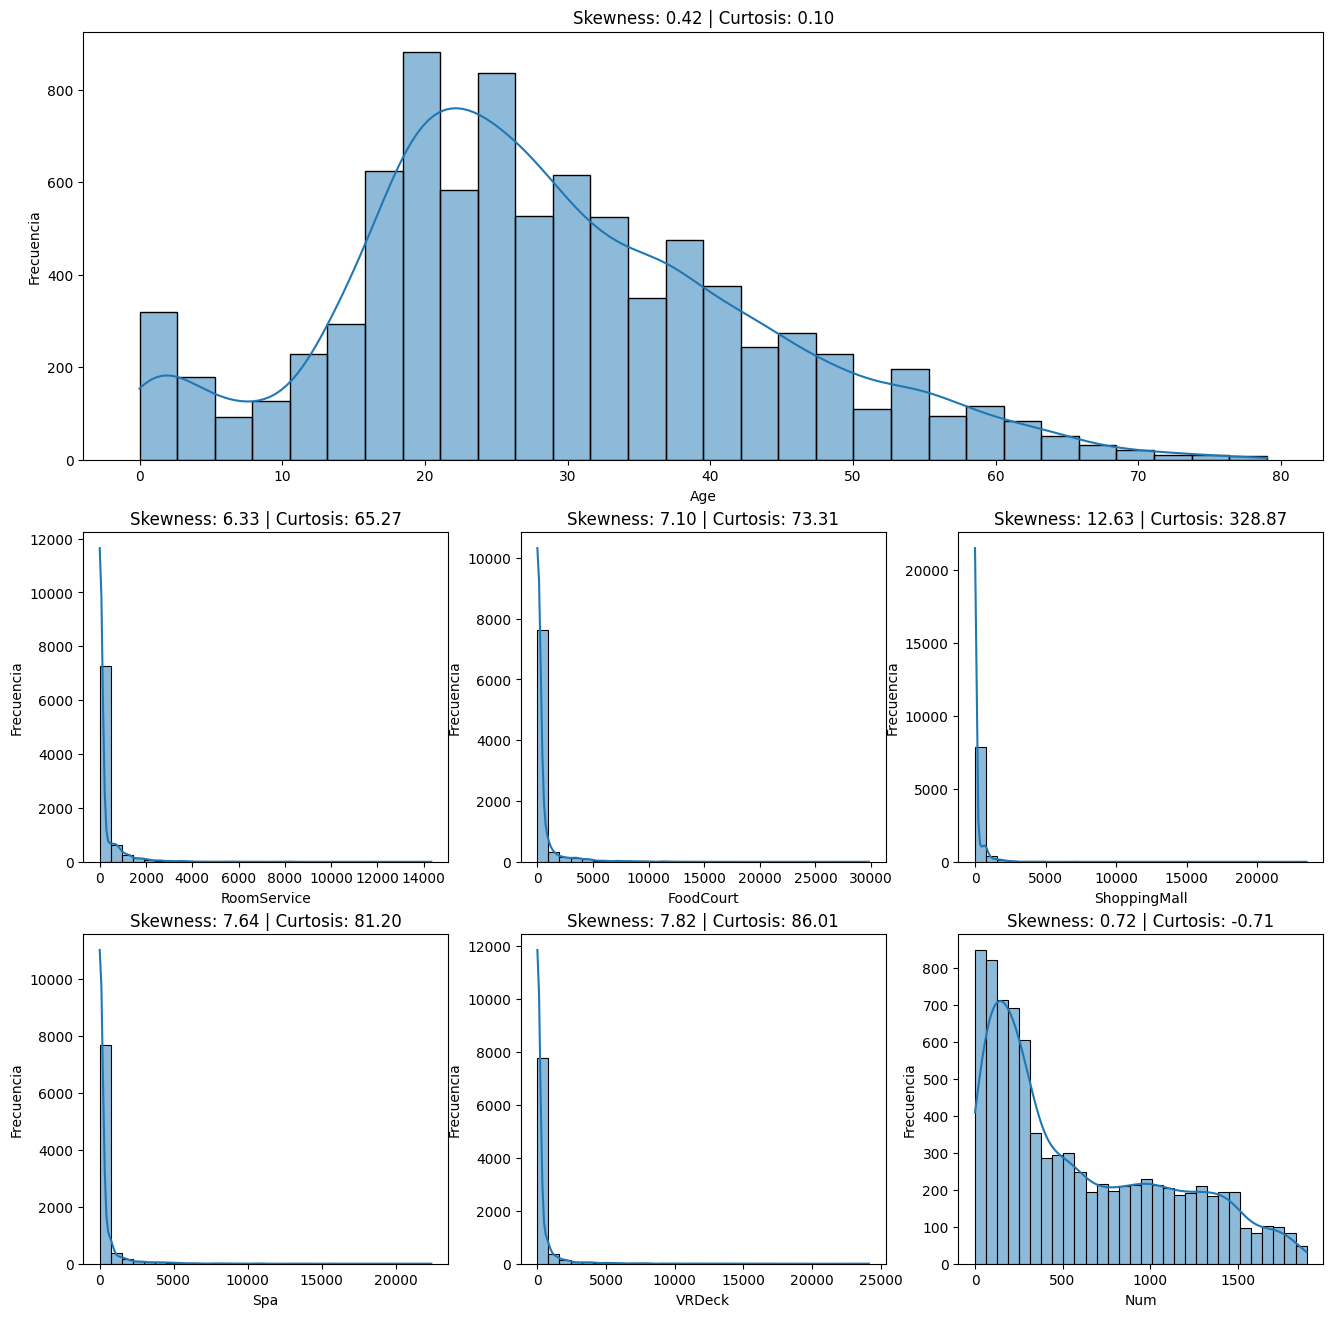

In [10]:
# Generamos algunas graficas para ver la distribución de los datos

# Variables numéricas
# histogramas con linea de densidad y skewness

fig = plt.figure(figsize=(16, 16))
gs = GridSpec(3, 3, figure=fig, height_ratios=[1.3, 1, 1]) 

for i, col in enumerate(numerical_cols):
    if col == "Age":
        ax = fig.add_subplot(gs[0, :])
    else:
        ax = fig.add_subplot(gs[(i+2)//3, (i+2)%3])
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=ax)
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
    skew = df[col].skew()
    curtosis = df[col].kurtosis()
    ax.set_title(f'Skewness: {skew:.2f} | Curtosis: {curtosis:.2f}')


Podemos observar como las graficas de los gastos muestran una gran cantidad de valores nulos, lo que indica que muchos pasajeros no utilizaron estos servicios. Tenemos 5 columnas de gastos, por lo que podemos crear una nueva columna que sume todos los gastos de cada pasajero y nos permita tener una mejor idea del gasto total de cada uno. Esta nueva columna será una variable numérica continua.

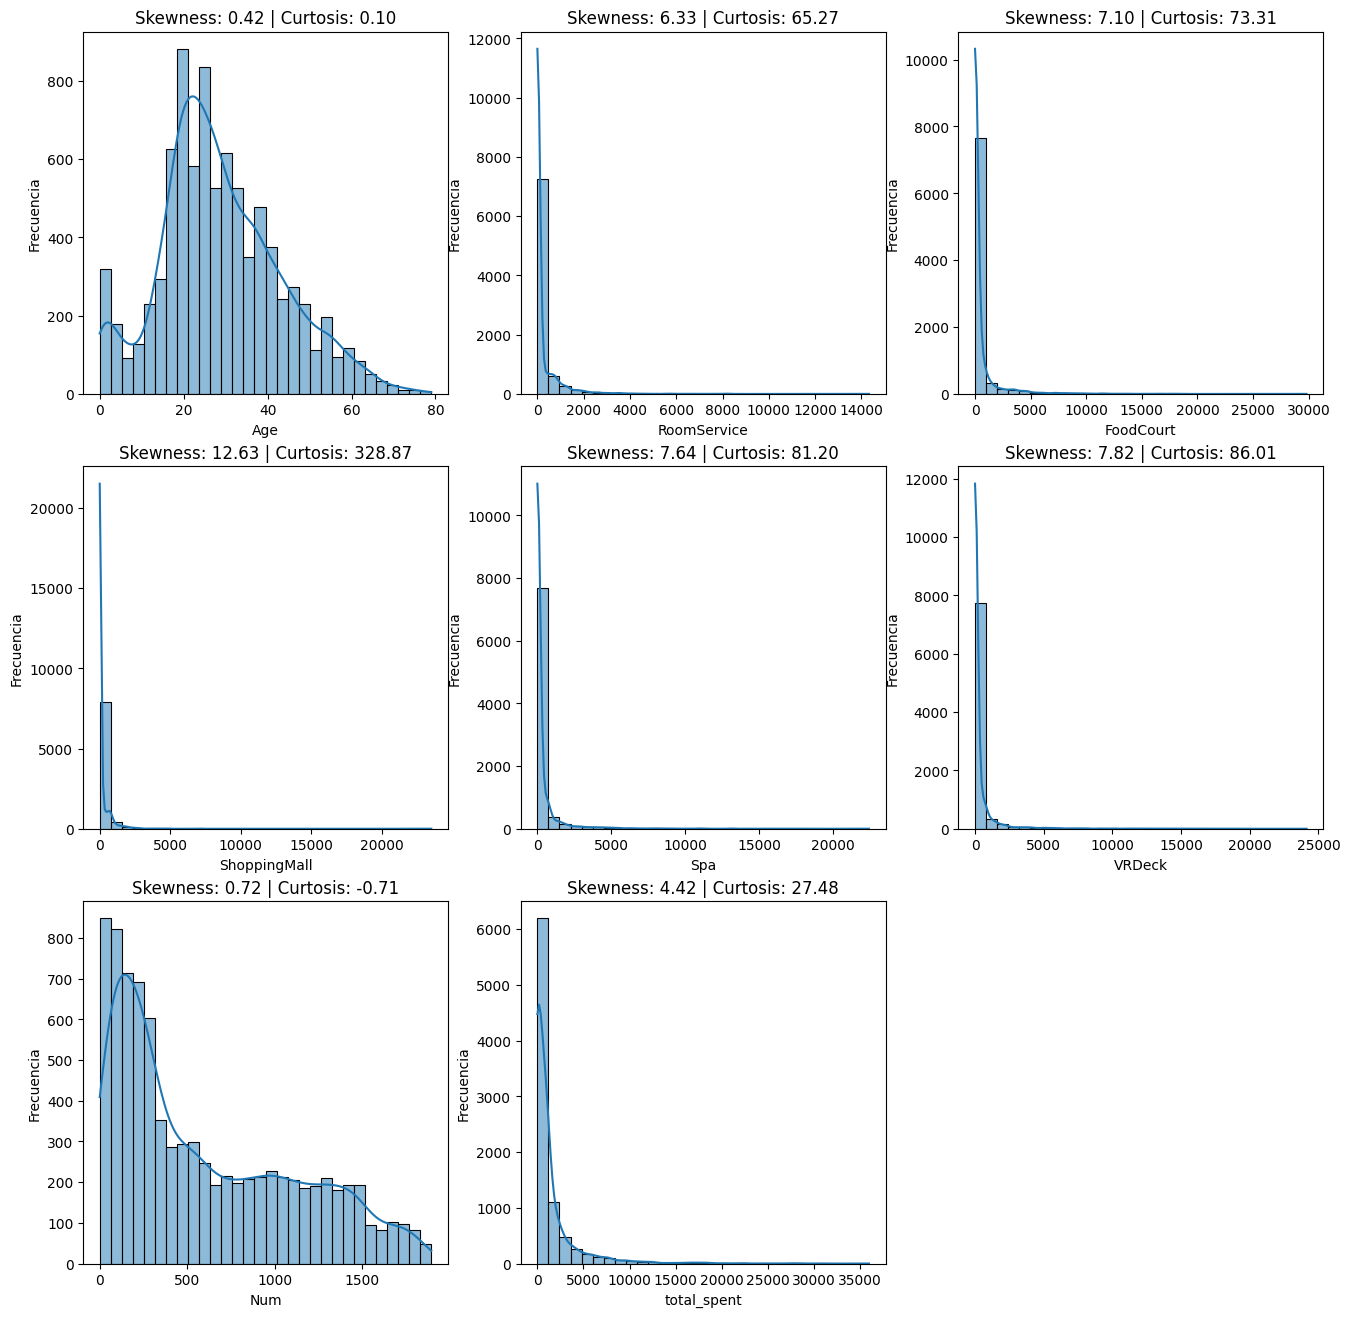

In [11]:
df["total_spent"] = df[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]].sum(axis=1)

numerical_cols = df.select_dtypes(include=[np.number]).columns

# Generamos de nuevo las graficas para ver la distribución de los datos, ahora con la nueva columna total_spent
fig = plt.figure(figsize=(16, 16))

for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i+1)   
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=plt.gca())
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    skew = df[col].skew()
    curtosis = df[col].kurtosis()
    plt.title(f'Skewness: {skew:.2f} | Curtosis: {curtosis:.2f}')


Con esta nueva columna logramos reducir el skewness de las variables de gastos, aunque sigue siendo alto, en el paso 3 se aplicará una transformación logarítmica para normalizar la distribución.

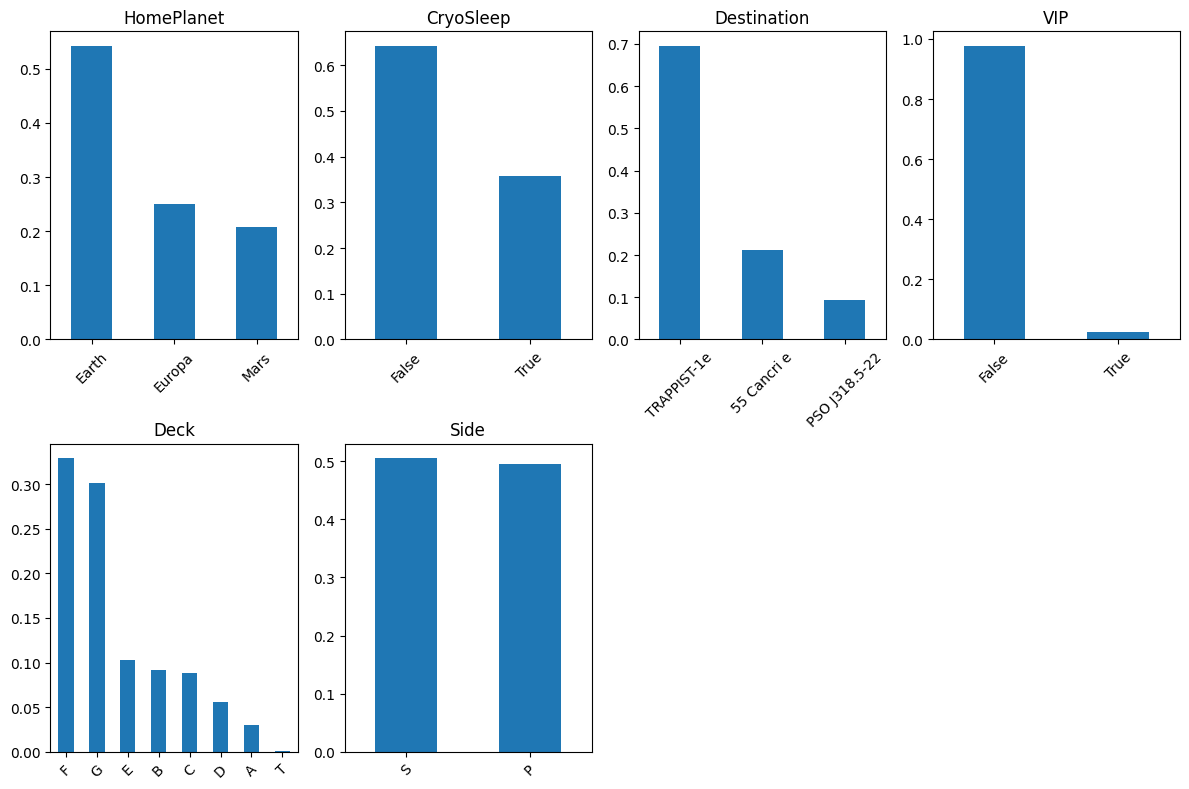

In [12]:
# Variales categoricas
plt.figure(figsize=(12, 8))

for i, col in enumerate(categorical_cols):
    plt.subplot(2, 4, i+1)
    df[col].value_counts(normalize=True).plot(kind='bar')
    plt.title(col)
    plt.xticks(rotation=45)
    plt.xlabel("")
    plt.tight_layout()


Text(0.5, 1.0, 'Correlación entre variables numéricas')

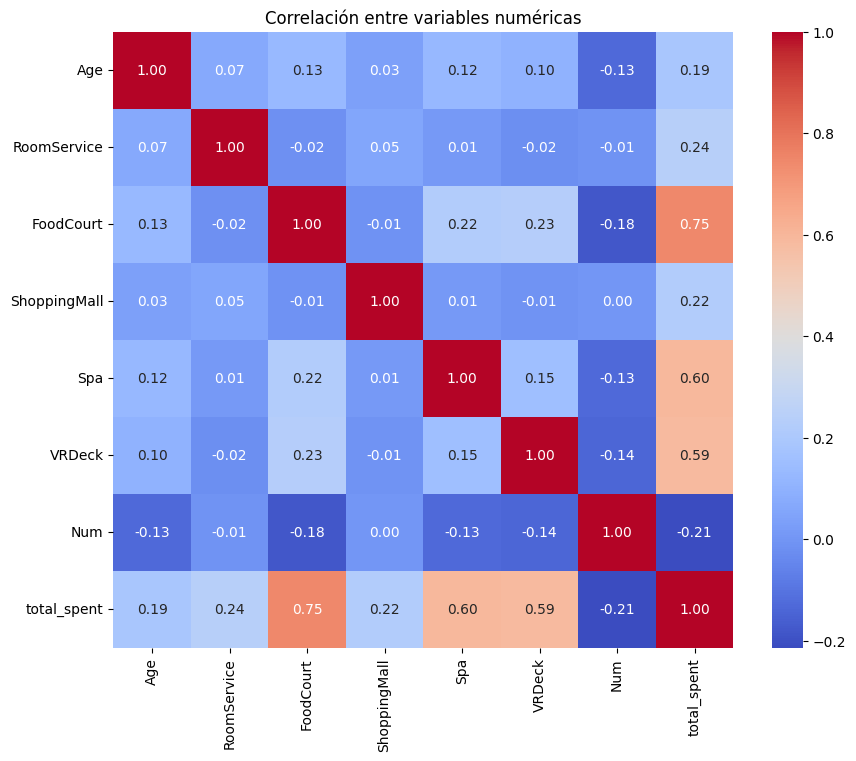

In [13]:
# Generamos ahora un heatmap para ver la correlación entre las variables numéricas
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlación entre variables numéricas")

Si descartamos la columna total_spent, que al ser la suma tendra una correlacion alta con las variables originales. El valor mas alto en la correlacion es 0.21, lo que indica que no hay una correlación fuerte entre las variables numéricas. Lo que nos permite conservar todas las variables para el modelo.

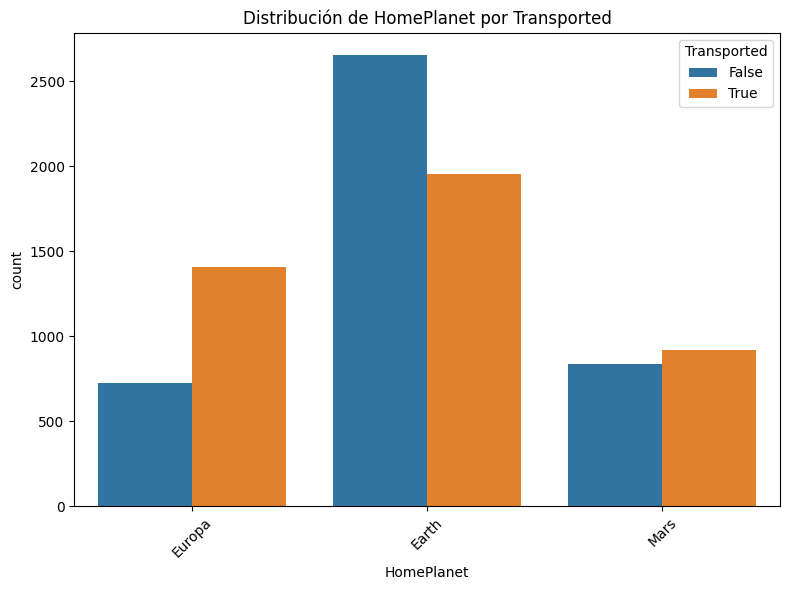

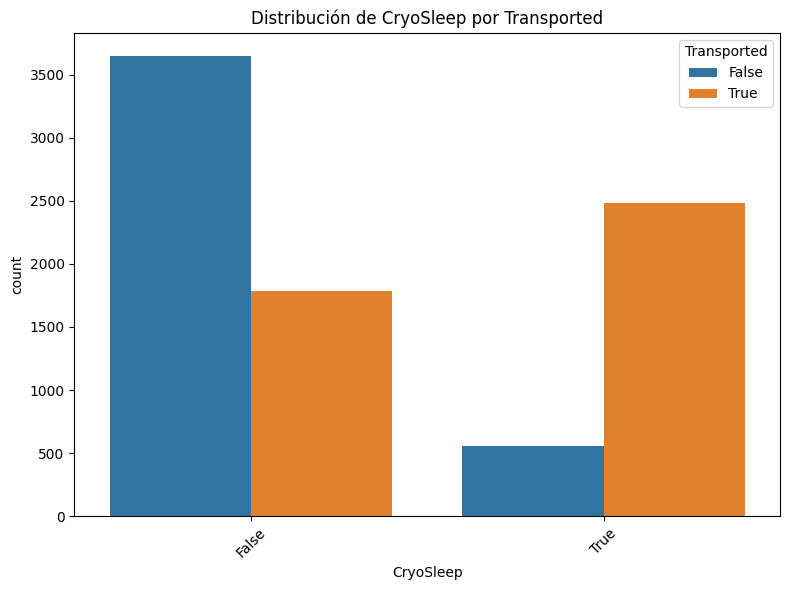

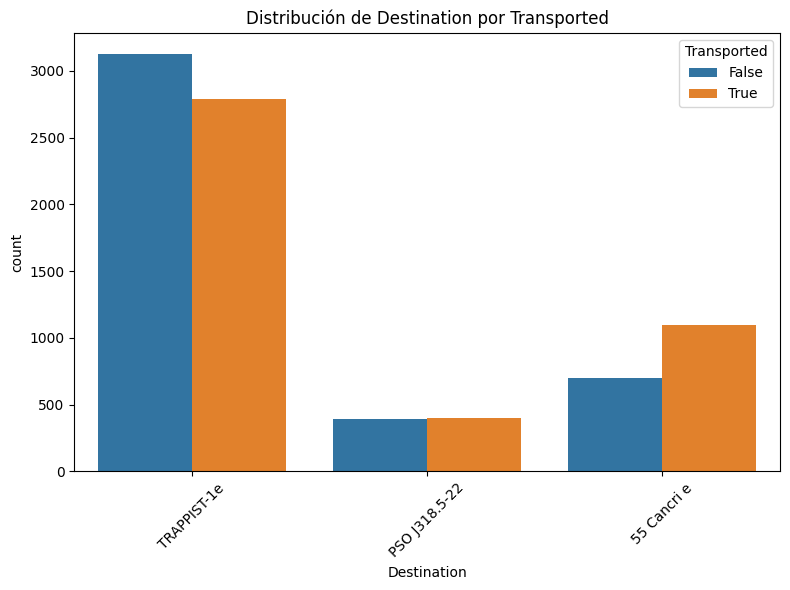

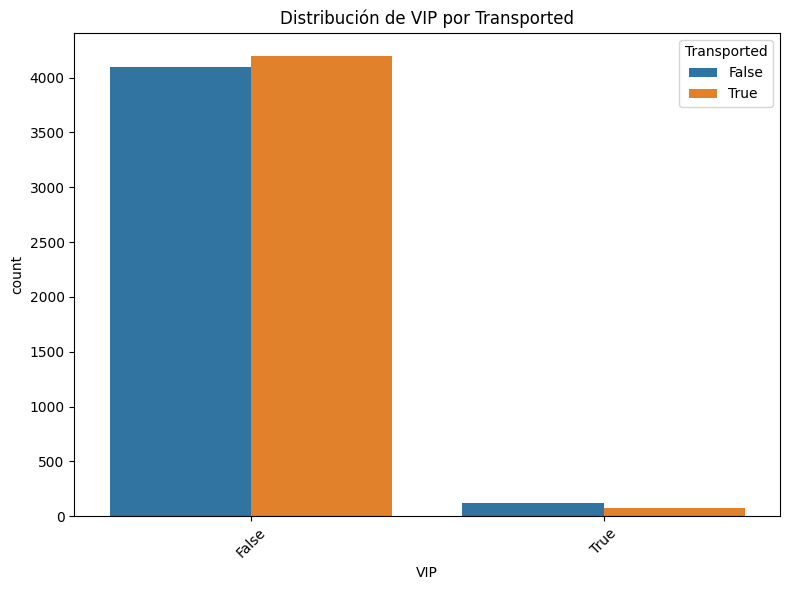

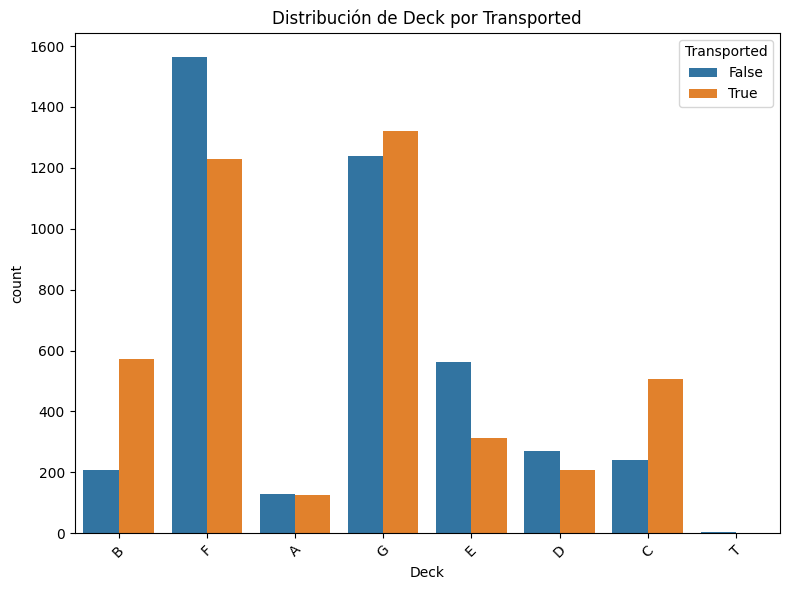

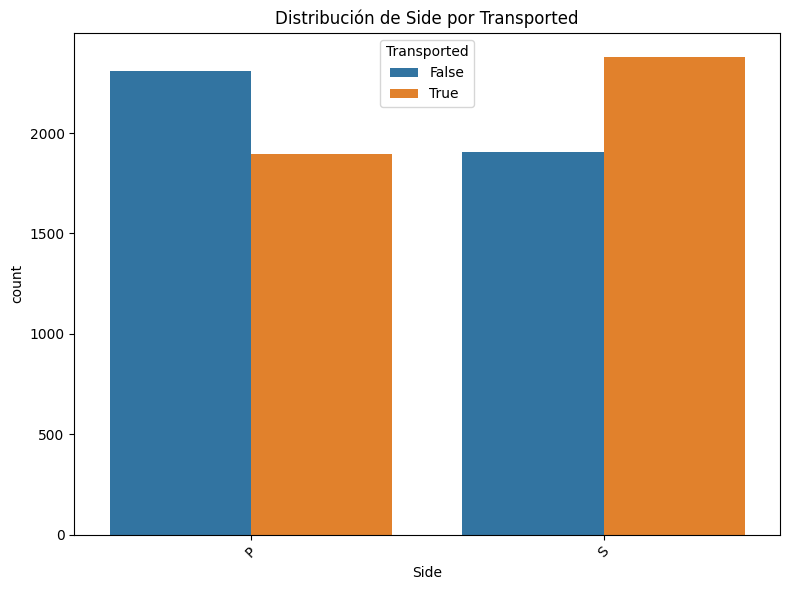

In [14]:
# Ahora revisaremos la relacion entre las variables categoricas y la variable objetivo

for col in categorical_cols:
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x=col, hue='Transported')
    plt.title(f"Distribución de {col} por Transported")
    plt.xticks(rotation=45)
    plt.tight_layout()

Hay algunas variables que tienen un mayor impacto, por ejemplo cyroSleep, de los pasajerons que eligieron entrar en cryosleep, la gran mayoría fueron transportados a otra dimensión, mientras que de los que no eligieron entrar en cryosleep, la gran mayoría no fueron transportados. Esto nos indica que esta variable es muy importante para el modelo. Otro importante parece sere el homePlanet, ya que los pasajeros que partieron de Europa fueron transportados en su mayoría, mientras que los pasajeros que partieron de Earth no fueron transportados en su mayoría.

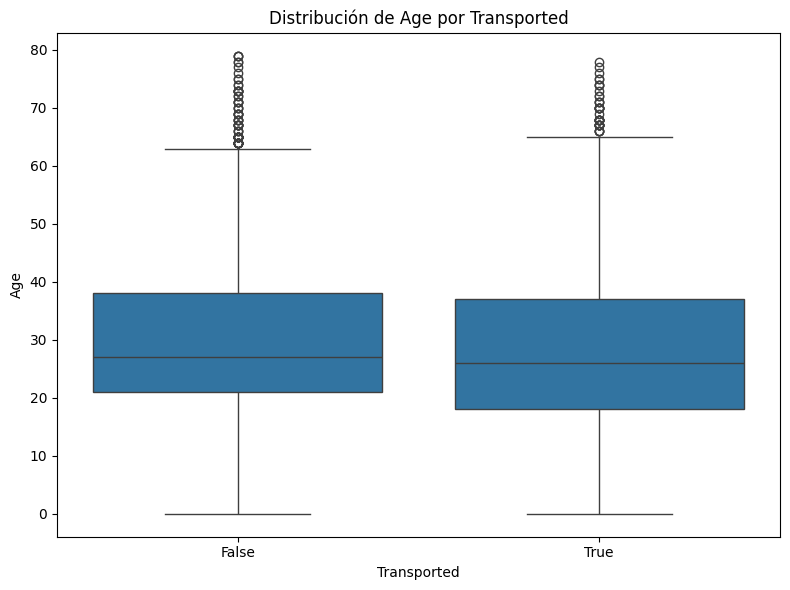

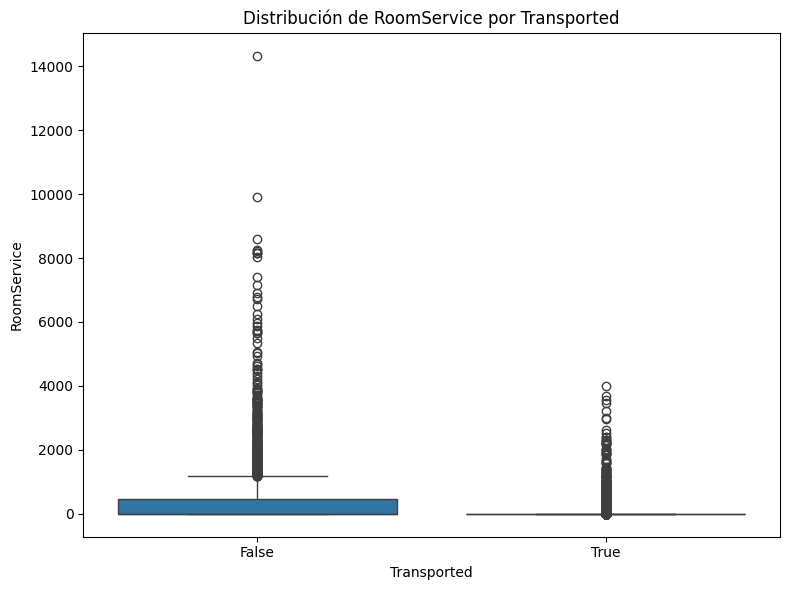

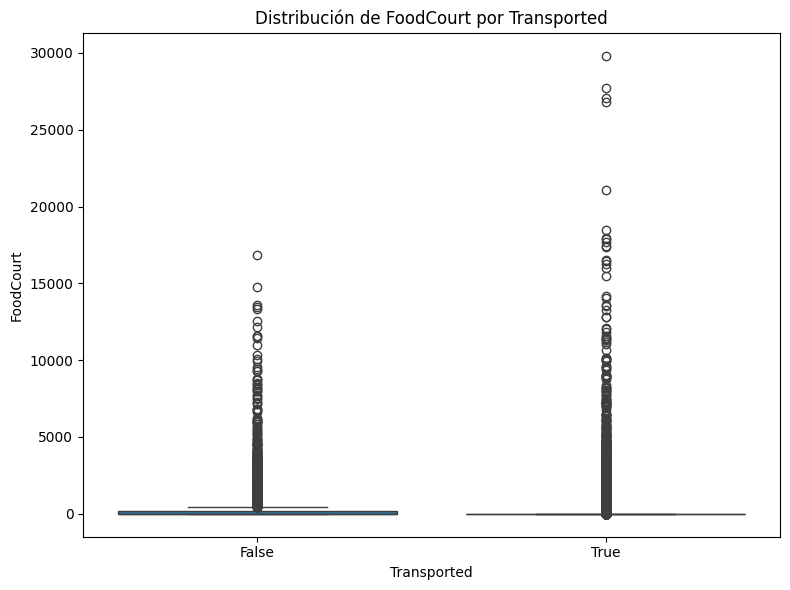

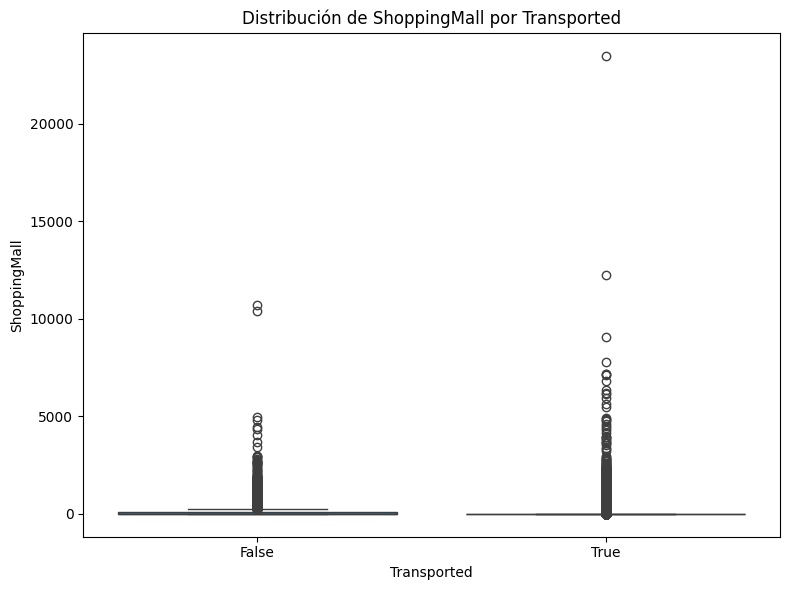

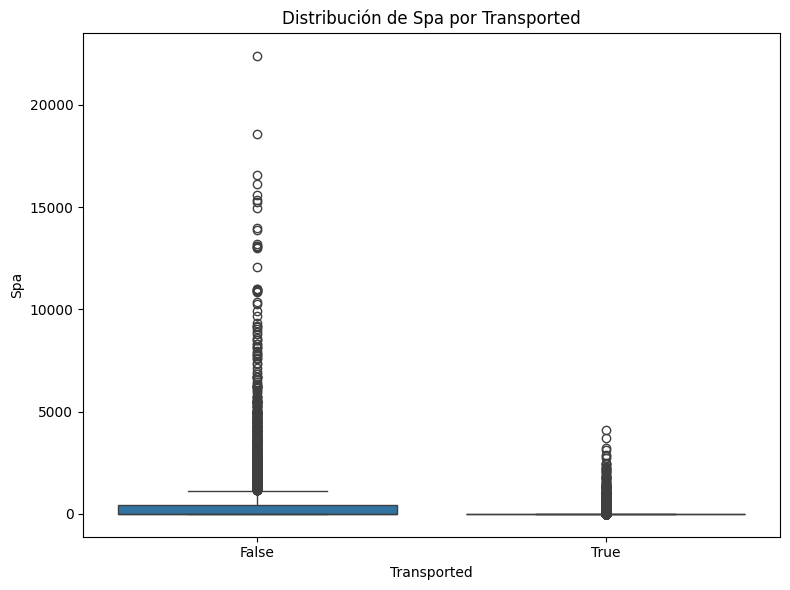

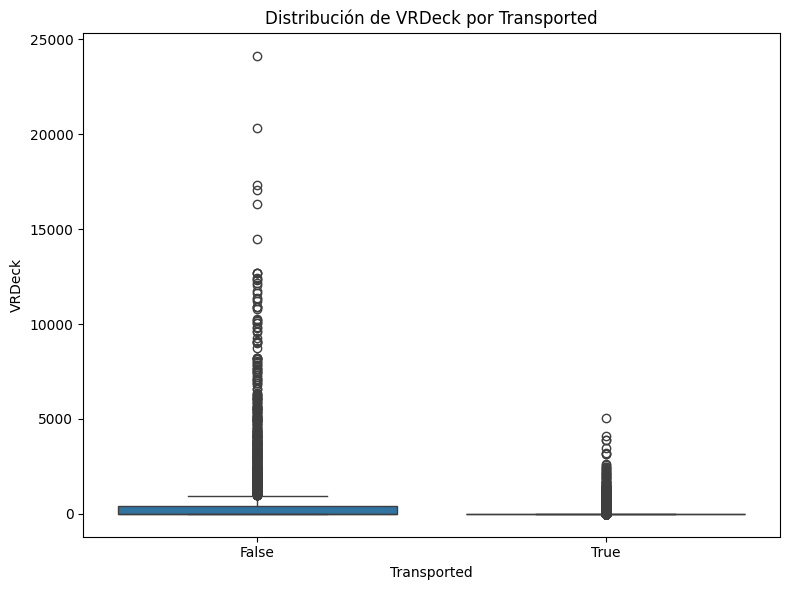

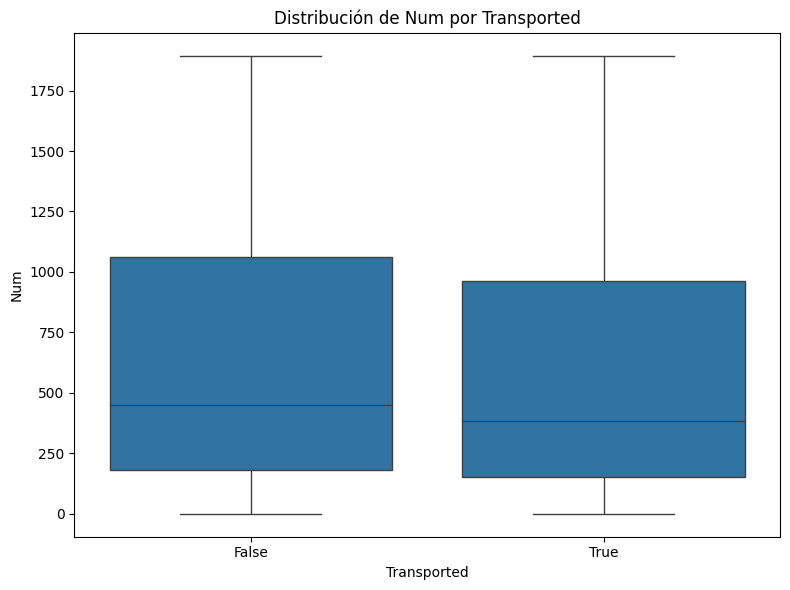

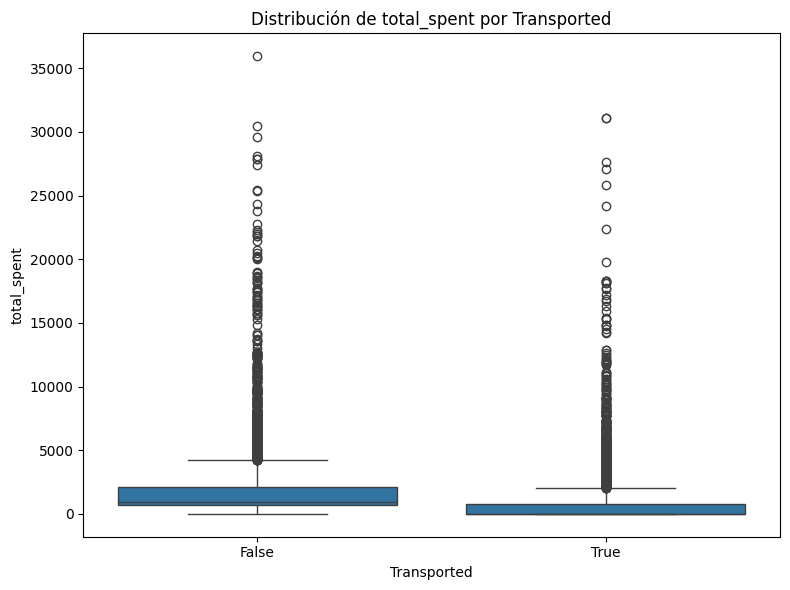

In [15]:
# numericas vs target

for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df, x='Transported', y=col)
    plt.title(f"Distribución de {col} por Transported")
    plt.tight_layout()

In [16]:
# Sacamos mediana de cada variable separando por transported

for col in numerical_cols:
    mediana_transportado = df[df['Transported'] == True][col].median()
    mediana_no_transportado = df[df['Transported'] == False][col].median()
    print(f"Mediana de {col} para Transported=True: {mediana_transportado}")
    print(f"Mediana de {col} para Transported=False: {mediana_no_transportado}")
    print("--------------------------------------------------")

Mediana de Age para Transported=True: 26.0
Mediana de Age para Transported=False: 27.0
--------------------------------------------------
Mediana de RoomService para Transported=True: 0.0
Mediana de RoomService para Transported=False: 1.0
--------------------------------------------------
Mediana de FoodCourt para Transported=True: 0.0
Mediana de FoodCourt para Transported=False: 0.0
--------------------------------------------------
Mediana de ShoppingMall para Transported=True: 0.0
Mediana de ShoppingMall para Transported=False: 0.0
--------------------------------------------------
Mediana de Spa para Transported=True: 0.0
Mediana de Spa para Transported=False: 4.0
--------------------------------------------------
Mediana de VRDeck para Transported=True: 0.0
Mediana de VRDeck para Transported=False: 1.0
--------------------------------------------------
Mediana de Num para Transported=True: 385.0
Mediana de Num para Transported=False: 448.5
-----------------------------------------

De las variables numericas, la que mas destaca es la de gastos, la diferencia entre la mediana de los pasajeros transportados y no transportados es de 900, aunque sea contra intuitivo los que gastaron mas dinero fueron los que menos fueron transportados. Esto puede tener una explicacion, hay pasajeros que estan en cryosleep, en este estado no pueden gastar dinero, en la siguiente celda exploramos esta relacion.

In [17]:
# gastos vs cryosleep

# pasajeron no en cyroSleep y gasto mayor a 0
non_cryosleep_spent_counts = df[(df['CryoSleep'] == False) & (df['total_spent'] > 0)].groupby(['Transported']).size().reset_index(name='counts')
display(non_cryosleep_spent_counts)
print("Porcentaje de pasajeros no en cryoSleep y gasto mayor a 0 que fueron transportados: {:.2f}%".format(non_cryosleep_spent_counts[non_cryosleep_spent_counts['Transported'] == True]['counts'].values[0] / non_cryosleep_spent_counts['counts'].sum() * 100))

# pasajeron no en cyroSleep y gasto igual a 0
cryosleep_no_spent_counts = df[(df['CryoSleep'] == False) & (df['total_spent'] == 0)].groupby(['Transported']).size().reset_index(name='counts')
display(cryosleep_no_spent_counts)
print("Porcentaje de pasajeros no en cryoSleep y gasto igual a 0 que fueron transportados: {:.2f}%".format(cryosleep_no_spent_counts[cryosleep_no_spent_counts['Transported'] == True]['counts'].values[0] / cryosleep_no_spent_counts['counts'].sum() * 100))

,Transported,counts
0,False,3451
1,True,1470


Porcentaje de pasajeros no en cryoSleep y gasto mayor a 0 que fueron transportados: 29.87%


,Transported,counts
0,False,199
1,True,319


Porcentaje de pasajeros no en cryoSleep y gasto igual a 0 que fueron transportados: 61.58%


Aun tomando en cuenta que los pasajeros en cryosleep no pueden gastar dinero, la relacion entre gastar y no ser transportado sigue siendo importante, ya que nos permite entender de entre los pasajeros que no esta en cryosleep, solo un 30% de los pasajeros que gastaron fueron transportados, mientras que un 60% de los pasajeros que no gastaron fueron transportados.

### Paso 3: Calidad de datos

Se revisan valores faltantes, duplicados y outliers. Las decisiones de limpieza que salen de este análisis se implementan en los scripts, no en este notebook.


In [18]:
# revisamos valores faltantes y duplicados
missing_values = df.isnull().sum()
print("Valores faltantes por columna:")
print(missing_values[missing_values > 0])

duplicated_rows = df.duplicated().sum()
print("Número de filas duplicadas: ", duplicated_rows)

Valores faltantes por columna:
HomePlanet      201
CryoSleep       217
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Deck            199
Num             199
Side            199
dtype: int64
Número de filas duplicadas:  15


Tenemos valores nulos en casi todas las columnas. La imputación (mediana para numéricas y moda para categóricas) se hace dentro del pipeline de `train.py`, ajustada solo con el conjunto de entrenamiento para evitar data leakage. Las reglas de negocio (pasajeros con gasto no pueden estar en CryoSleep y pasajeros en CryoSleep no gastan) se aplican en `dataset.py`.

Sobre los valores duplicados, nos muestra que son 15, pero esto puede significar que hay perfiles similares, lo comprobaremos en la siguiente celda, usando el dataframe original, podemos ver si el nombre cambia, de ser asi son personas diferentes y no desecharemos el duplicado, si el nombre es igual, entonces si desecharemos el duplicado.


In [19]:
# cargamos el dataframe original para revisar los duplicados
df_original = pd.read_csv(RAW_DATA_DIR / 'dataset.csv')

# drop de pasagerId, solo contamos el name como diferencia
df_original = df_original.drop(columns=['PassengerId'])
duplicated_rows_original = df_original.duplicated().sum()
print("Número de filas duplicadas en el dataframe original: ", duplicated_rows_original)


Número de filas duplicadas en el dataframe original:  0


Se demuestra que los duplicados son personas diferentes, por lo que no desecharemos los duplicados.

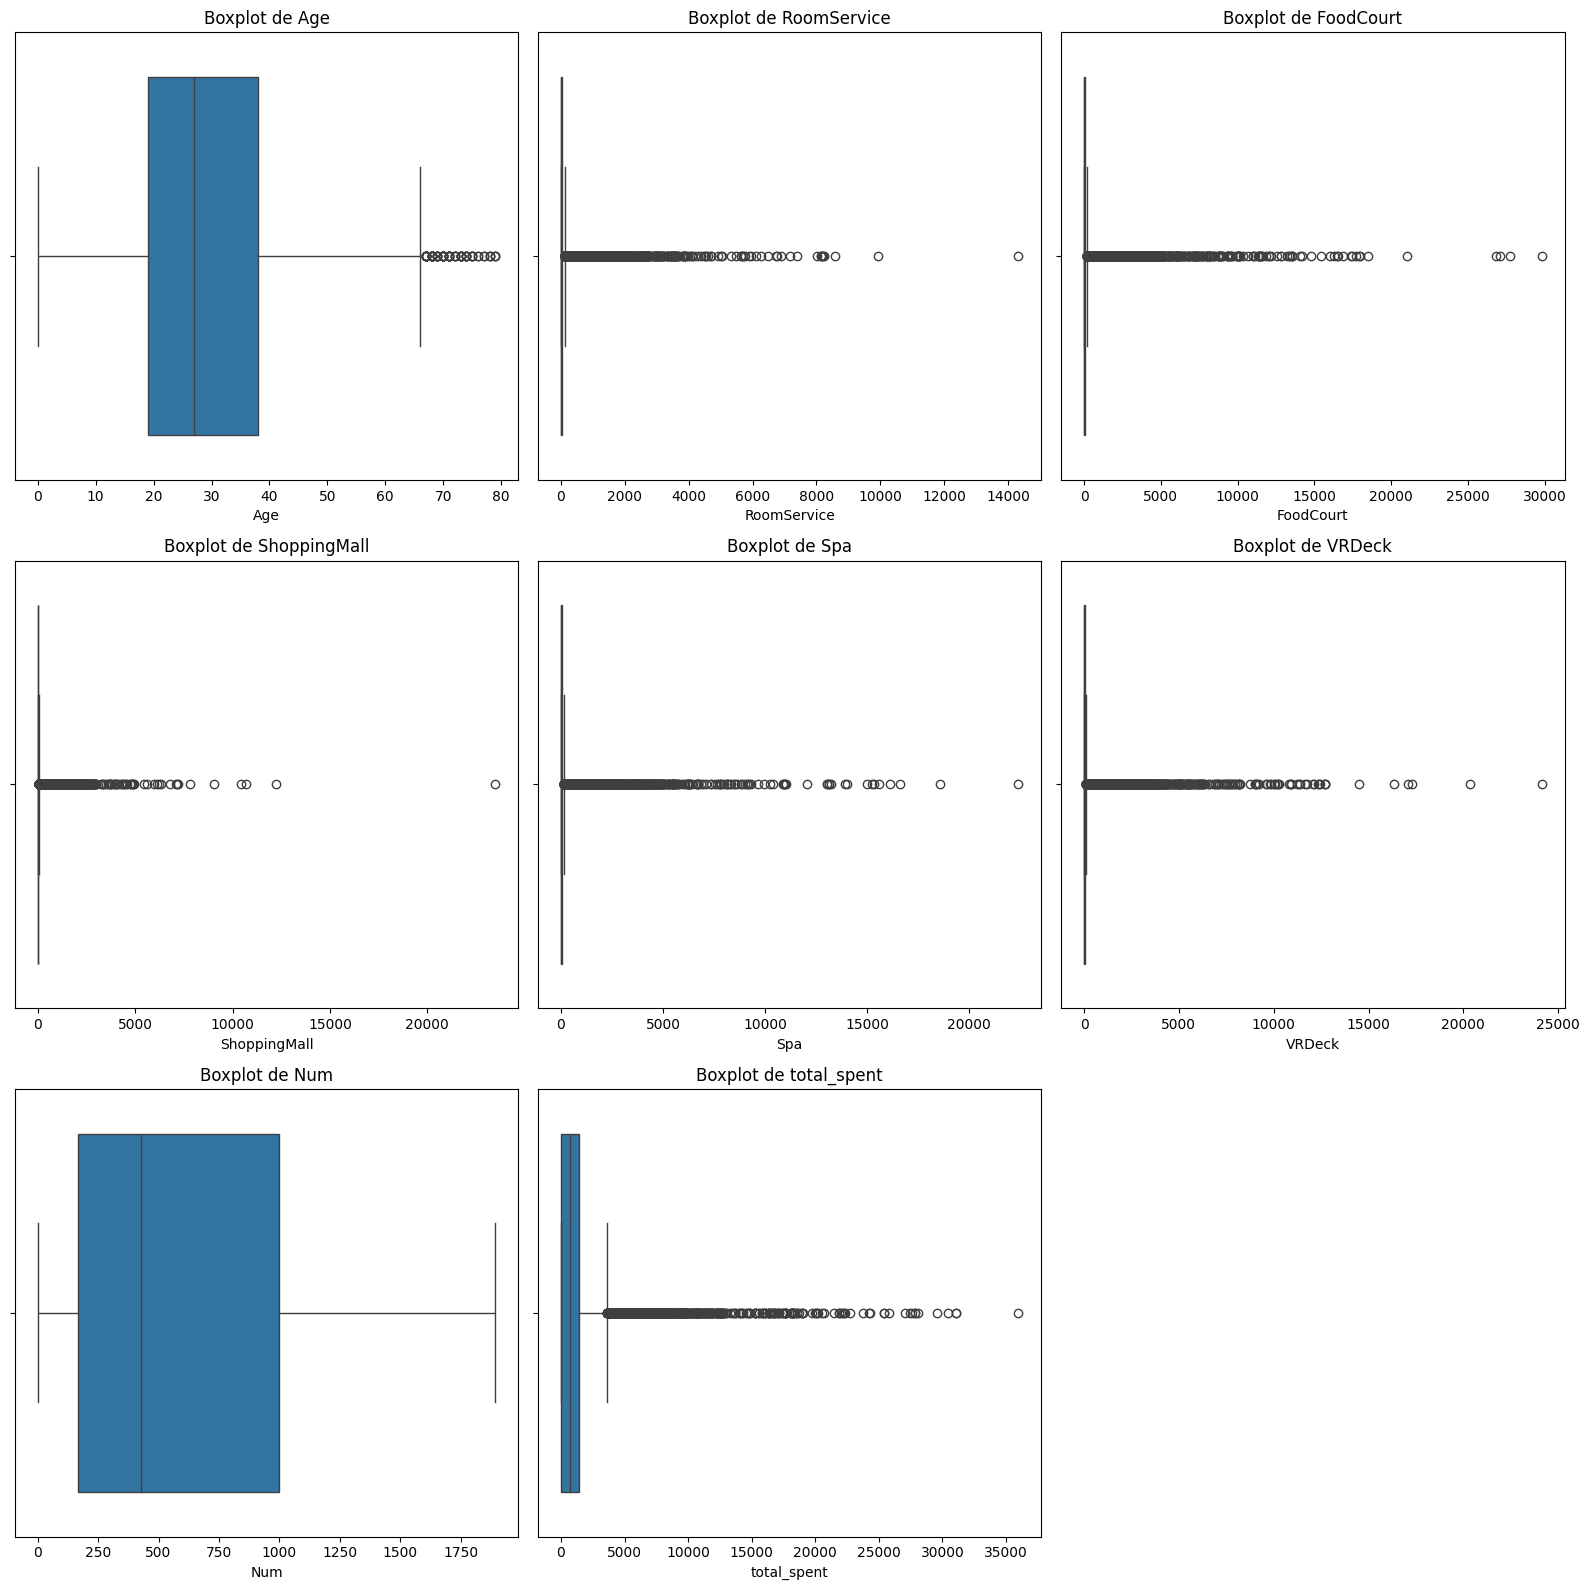

In [20]:
# Para detectar valores atipicos (outliers), podemos usar boxplots para cada variable numérica 
# y ver si hay valores que se encuentran fuera del rango intercuartílico (IQR).

fig = plt.figure(figsize=(16, 16))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i+1)
    sns.boxplot(data=df, x=col)
    plt.title(f"Boxplot de {col}")
    plt.tight_layout()

In [21]:
# mostramos la cantidad de outliers por variable numérica
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"Cantidad de outliers en {col}: {outliers.shape[0]}")

Cantidad de outliers en Age: 77
Cantidad de outliers en RoomService: 1861
Cantidad de outliers en FoodCourt: 1823
Cantidad de outliers en ShoppingMall: 1829
Cantidad de outliers en Spa: 1788
Cantidad de outliers en VRDeck: 1809
Cantidad de outliers en Num: 0
Cantidad de outliers en total_spent: 934


La regla menciona que los valores que se encuentran fuera de 1.5 veces el IQR por encima del tercer cuartil o por debajo del primer cuartil se consideran atípicos. Pero en este caso, en las variables de gastos, tenemos demasiados valores fuera de este rango, esto se debe a que la mayor parte de los pasajeros no gastaron dinero, esto genera que, por ejemplo, si gastaste 100 en el SPA ya es considerado un outlier. 1900 es un ~20% del dataset, no es correcto que el 20% de los datos sean outliers.

La regla del IQR funciona con una distribucin mas o menos simetrica, algo que no tenemos en estas variales de gastos. Para reducir el sesgo, aplicaremos una transformación logarítmica a las columnas de gastos.

Con la variable Age, los valores fuera del rango son 162 (arriba de ~62 años), pero estos representan casos reales, no errores, por lo que no los eliminaremos.

Num no tiene outliers.


Cantidad de outliers en RoomService_log: 0
Cantidad de outliers en FoodCourt_log: 0
Cantidad de outliers en ShoppingMall_log: 28
Cantidad de outliers en Spa_log: 0
Cantidad de outliers en VRDeck_log: 5
Cantidad de outliers en total_spent_log: 0


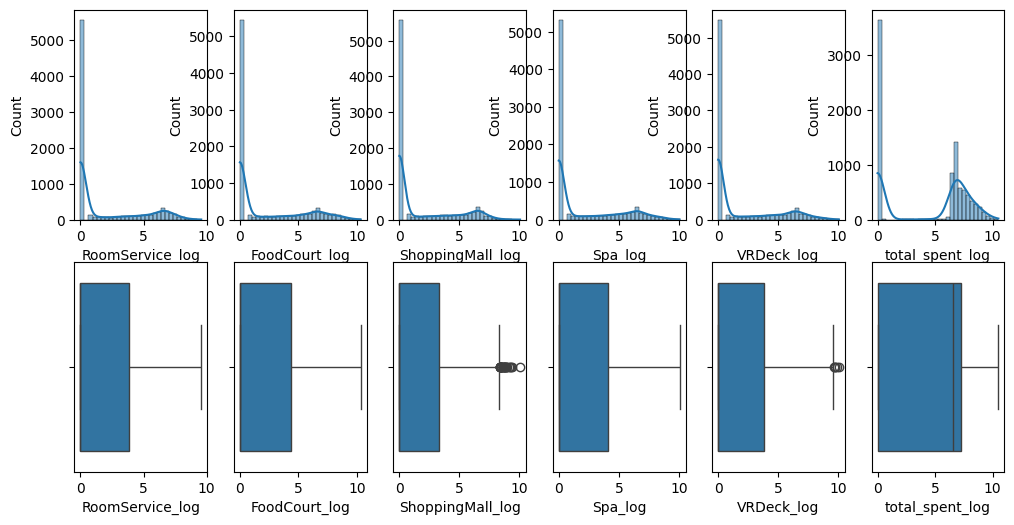

In [22]:
# aplicamos un log1p a las columnas de gastos
plt.figure(figsize=(12, 6))
col_gastos = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "total_spent"]

for col in col_gastos:
    df[col + '_log'] = np.log1p(df[col])
    plt.subplot(2, 6, col_gastos.index(col)+1)
    # histograma
    sns.histplot(data=df, x=col + '_log', kde=True, bins=30)
    # boxplot
    plt.subplot(2, 6, col_gastos.index(col)+7)
    sns.boxplot(data=df, x=col + '_log')

    # Calculamos la cantidad de outliers en la variable logarítmica
    Q1 = df[col + '_log'].quantile(0.25)
    Q3 = df[col + '_log'].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col + '_log'] < (Q1 - 1.5 * IQR)) | (df[col + '_log'] > (Q3 + 1.5 * IQR))]
    print(f"Cantidad de outliers en {col}_log: {outliers.shape[0]}")


### Conclusiones que se llevaron a los scripts

- `Name` y `PassengerId` se eliminan (`dataset.py`).
- `Cabin` se separa en `Deck`, `Num` y `Side`, y `Num` se convierte a numérico (`dataset.py`).
- Si un pasajero tiene gasto mayor a 0 y `CryoSleep` es nulo, se asume `CryoSleep = False` (`dataset.py`).
- Si un pasajero está en `CryoSleep`, sus gastos faltantes se rellenan con 0 (`dataset.py`).
- Los duplicados corresponden a pasajeros distintos, por lo que se conservan.
- Los outliers de `Age` son casos reales y se conservan; a las columnas de gasto se les aplica `log1p` para reducir el sesgo (`features.py`).
- `total_spent` no se usa en el modelo: en el baseline, las columnas de gasto por separado dieron mejor accuracy.
- La imputación con mediana y moda, el OneHotEncoder y el StandardScaler se ajustan solo con train dentro del pipeline (`train.py`).
